<a href="https://colab.research.google.com/github/derykian/2418005_Data_Visualization/blob/main/2418005DataVisualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1. Import library

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

#2. Mengambil dataset dari GitHub

In [2]:
url = (
    "https://raw.githubusercontent.com/"
    "shantanu1109/IBM-HR-Analytics-Employee-Attrition-and-Performance-Prediction/"
    "main/DATASET/IBM-HR-Analytics-Employee-Attrition-and-Performance.csv"
)

df = pd.read_csv(url)

print("Ukuran dataset:", df.shape)
print("Jumlah baris:", len(df))
print("Jumlah kolom:", len(df.columns))

display(df.head())

Ukuran dataset: (1470, 35)
Jumlah baris: 1470
Jumlah kolom: 35


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


#3. Memeriksa kualitas data

In [3]:
print("Informasi dataset:")
df.info()

print("\nNilai kosong per kolom:")
display(df.isna().sum().to_frame("Missing Values"))

print("\nJumlah baris duplikat:", df.duplicated().sum())
print("\nJumlah departemen:", df["Department"].nunique())

print("\nJumlah karyawan per departemen:")
display(df["Department"].value_counts().to_frame("Jumlah Karyawan"))

print("\nStatistik deskriptif:")
display(df.describe(include="all").transpose())

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLe

,Missing Values
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0



Jumlah baris duplikat: 0

Jumlah departemen: 3

Jumlah karyawan per departemen:


,Jumlah Karyawan
Department,
Research & Development,961
Sales,446
Human Resources,63



Statistik deskriptif:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
Attrition,1470,2,No,1233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BusinessTravel,1470,3,Travel_Rarely,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1470.0,NaN,NaN,NaN,802.485714,403.5091,102.0,465.0,802.0,1157.0,1499.0
Department,1470,3,Research & Development,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1470.0,NaN,NaN,NaN,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Education,1470.0,NaN,NaN,NaN,2.912925,1.024165,1.0,2.0,3.0,4.0,5.0
EducationField,1470,6,Life Sciences,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1470.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
EmployeeNumber,1470.0,NaN,NaN,NaN,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0


#4. Pembersihan dan persiapan data

In [4]:
data = df.copy()

# Hapus baris duplikat jika ada
data = data.drop_duplicates().copy()

# Hapus kolom konstan dan identifier
kolom_hapus = [
    kolom for kolom in ["EmployeeCount", "Over18", "StandardHours",
                        "EmployeeNumber"]
    if kolom in data.columns
]

data = data.drop(columns=kolom_hapus)

# Pendapatan tahunan merupakan estimasi dari pendapatan bulanan
data["EstimatedAnnualIncome"] = data["MonthlyIncome"] * 12

print("Ukuran data setelah persiapan:", data.shape)
print("Jumlah data kosong:", data.isna().sum().sum())

display(data.head())

Ukuran data setelah persiapan: (1470, 32)
Jumlah data kosong: 0


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,EstimatedAnnualIncome
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Yes,11,3,1,0,8,0,1,6,4,0,5,71916
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,No,23,4,4,1,10,3,3,10,7,1,7,61560
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Yes,15,3,2,0,7,3,3,0,0,0,0,25080
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Yes,11,3,3,0,8,3,3,8,7,3,0,34908
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,No,12,3,4,1,6,3,3,2,2,2,2,41616


#5. Histogram distribusi pendapatan bulanan

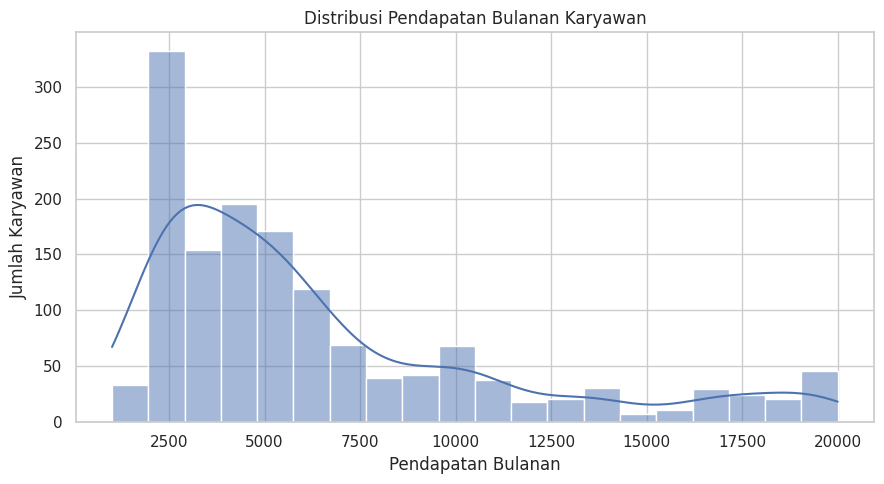

Rata-rata pendapatan bulanan: 6,502.93
Median pendapatan bulanan: 4,919.00
Pendapatan minimum: 1,009
Pendapatan maksimum: 19,999


In [5]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=data,
    x="MonthlyIncome",
    bins=20,
    kde=True
)

plt.title("Distribusi Pendapatan Bulanan Karyawan")
plt.xlabel("Pendapatan Bulanan")
plt.ylabel("Jumlah Karyawan")
plt.tight_layout()
plt.show()

print(f"Rata-rata pendapatan bulanan: {data['MonthlyIncome'].mean():,.2f}")
print(f"Median pendapatan bulanan: {data['MonthlyIncome'].median():,.2f}")
print(f"Pendapatan minimum: {data['MonthlyIncome'].min():,.0f}")
print(f"Pendapatan maksimum: {data['MonthlyIncome'].max():,.0f}")

#6. Bar chart jumlah karyawan per departemen

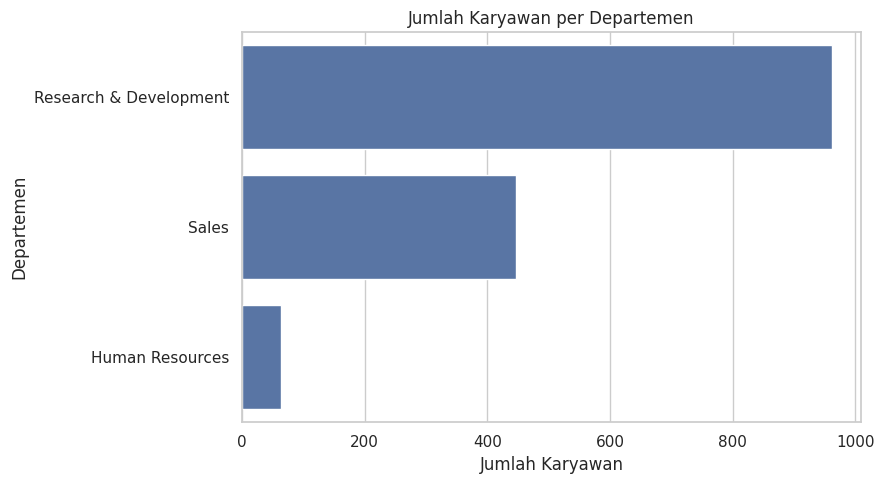

,Jumlah Karyawan
Department,
Research & Development,961
Sales,446
Human Resources,63


In [6]:
department_counts = data["Department"].value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(
    x=department_counts.values,
    y=department_counts.index
)

plt.title("Jumlah Karyawan per Departemen")
plt.xlabel("Jumlah Karyawan")
plt.ylabel("Departemen")
plt.tight_layout()
plt.show()

display(department_counts.rename("Jumlah Karyawan").to_frame())

#7. Boxplot pendapatan berdasarkan departemen

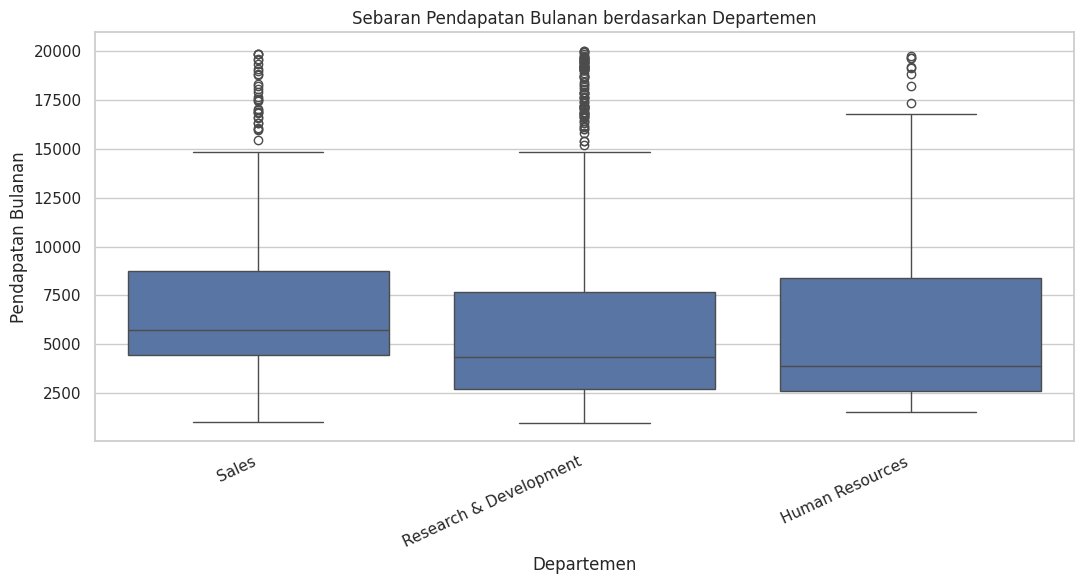

,count,mean,median,min,max
Department,,,,,
Sales,446,6959.17,5754.5,1052,19847
Research & Development,961,6281.25,4374.0,1009,19999
Human Resources,63,6654.51,3886.0,1555,19717


In [7]:
department_order = (
    data.groupby("Department")["MonthlyIncome"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(11, 6))
sns.boxplot(
    data=data,
    x="Department",
    y="MonthlyIncome",
    order=department_order
)

plt.title("Sebaran Pendapatan Bulanan berdasarkan Departemen")
plt.xlabel("Departemen")
plt.ylabel("Pendapatan Bulanan")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

salary_summary = (
    data.groupby("Department")["MonthlyIncome"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("median", ascending=False)
)

display(salary_summary.round(2))

#8. Scatter plot masa kerja dan pendapatan

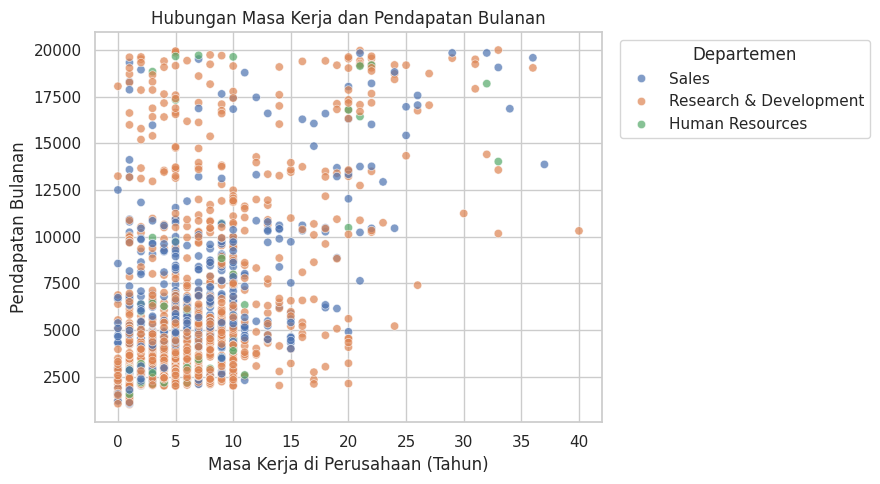

Korelasi Pearson: 0.514


In [8]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=data,
    x="YearsAtCompany",
    y="MonthlyIncome",
    hue="Department",
    alpha=0.7
)

plt.title("Hubungan Masa Kerja dan Pendapatan Bulanan")
plt.xlabel("Masa Kerja di Perusahaan (Tahun)")
plt.ylabel("Pendapatan Bulanan")
plt.legend(title="Departemen", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

correlation = data["YearsAtCompany"].corr(data["MonthlyIncome"])

print(f"Korelasi Pearson: {correlation:.3f}")

#9. Line chart tingkat attrition berdasarkan masa kerja

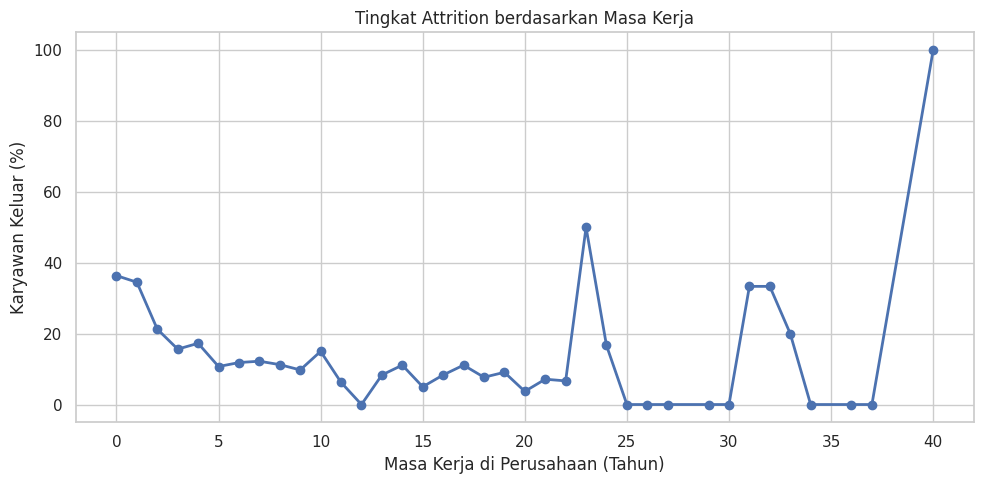

,Attrition Rate (%)
YearsAtCompany,
0,36.36
1,34.50
2,21.26
3,15.62
4,17.27
5,10.71
6,11.84
7,12.22
8,11.25


In [9]:
attrition_by_tenure = (
    data.assign(
        LeftCompany=data["Attrition"].eq("Yes").astype(int)
    )
    .groupby("YearsAtCompany")["LeftCompany"]
    .mean()
    .mul(100)
)

plt.figure(figsize=(10, 5))
plt.plot(
    attrition_by_tenure.index,
    attrition_by_tenure.values,
    marker="o",
    linewidth=2
)

plt.title("Tingkat Attrition berdasarkan Masa Kerja")
plt.xlabel("Masa Kerja di Perusahaan (Tahun)")
plt.ylabel("Karyawan Keluar (%)")
plt.tight_layout()
plt.show()

display(
    attrition_by_tenure.rename("Attrition Rate (%)")
    .round(2)
    .to_frame()
)

#10. Heatmap korelasi variabel numerik

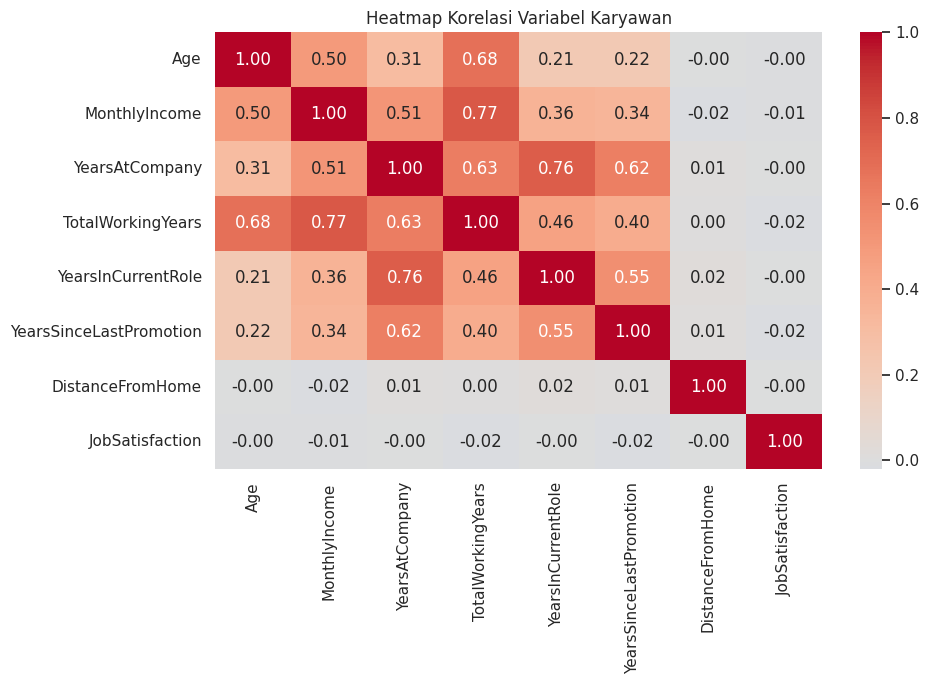

In [10]:
numeric_columns = [
    "Age",
    "MonthlyIncome",
    "YearsAtCompany",
    "TotalWorkingYears",
    "YearsInCurrentRole",
    "YearsSinceLastPromotion",
    "DistanceFromHome",
    "JobSatisfaction"
]

correlation_matrix = data[numeric_columns].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Heatmap Korelasi Variabel Karyawan")
plt.tight_layout()
plt.show()

#11. Insight utama dan kesimpulan otomatis

In [11]:
attrition_rate = data["Attrition"].eq("Yes").mean() * 100

highest_income_department = (
    data.groupby("Department")["MonthlyIncome"].median().idxmax()
)

highest_income_median = (
    data.groupby("Department")["MonthlyIncome"].median().max()
)

highest_attrition_group = attrition_by_tenure.idxmax()
highest_attrition_rate = attrition_by_tenure.max()

print("KESIMPULAN DATA VISUALIZATION")
print("=" * 45)
print(f"Jumlah karyawan: {len(data):,}")
print(f"Jumlah departemen: {data['Department'].nunique()}")
print(f"Tingkat attrition keseluruhan: {attrition_rate:.2f}%")

print(
    f"Departemen dengan median pendapatan tertinggi: "
    f"{highest_income_department}"
)
print(f"Median pendapatannya: {highest_income_median:,.0f}")

print(
    f"Tingkat attrition tertinggi berdasarkan masa kerja: "
    f"{highest_attrition_rate:.2f}% pada masa kerja "
    f"{highest_attrition_group} tahun."
)

print("\nInterpretasi:")
print(
    "Visualisasi membantu memahami distribusi pendapatan, "
    "komposisi departemen, hubungan antarvariabel, dan pola attrition."
)
print(
    "Hasil bersifat deskriptif dan hanya menggambarkan dataset yang dianalisis."
)

KESIMPULAN DATA VISUALIZATION
Jumlah karyawan: 1,470
Jumlah departemen: 3
Tingkat attrition keseluruhan: 16.12%
Departemen dengan median pendapatan tertinggi: Sales
Median pendapatannya: 5,754
Tingkat attrition tertinggi berdasarkan masa kerja: 100.00% pada masa kerja 40 tahun.

Interpretasi:
Visualisasi membantu memahami distribusi pendapatan, komposisi departemen, hubungan antarvariabel, dan pola attrition.
Hasil bersifat deskriptif dan hanya menggambarkan dataset yang dianalisis.
